<a href="https://colab.research.google.com/github/sitiaisy721-star/Analisis-Regresi-Berganda/blob/main/Regresi_Berganda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Latihan Regresi Linear Berganda (Data Panel)**


# Import library


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Load data

In [17]:

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

KOTA_LIST = ["Kota Pekanbaru", "Kota Jambi", "Kota Dumai"]
df = df[df["Kota"].isin(KOTA_LIST)].copy()
df.head()

,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
231,Kota Dumai,2014,62.73,36.84,26.96,84.93,38.68,45.76,56.49,71.07,...,239.18,154.77,224.17,181.17,299.17,9.17,4.93,0.39,84.51,2.76
232,Kota Dumai,2015,50.18,22.45,32.55,69.82,46.37,57.42,56.32,94.01,...,160.57,199.82,231.33,209.84,237.70,10.20,5.78,0.35,65.13,4.39
233,Kota Dumai,2016,44.94,27.90,29.34,105.16,56.81,38.15,38.10,138.25,...,226.85,178.43,259.09,134.50,211.18,9.46,3.64,0.42,75.59,3.02
234,Kota Dumai,2017,48.12,19.56,37.30,85.46,63.63,64.79,61.12,99.69,...,147.31,122.05,293.61,276.72,138.82,9.07,7.18,0.47,83.67,3.53
235,Kota Dumai,2018,41.19,51.53,30.97,102.82,42.89,56.62,60.67,119.84,...,107.22,51.62,293.90,196.84,62.29,11.12,3.11,0.42,66.33,3.58


# Struktur Data Panel


In [18]:
# data panel = banyak kota (cross section) x banyak tahun (time series)
print("jumlah kota :", df['Kota'].nunique())
print("jumlah tahun:", df['Tahun'].nunique())
print("jumlah baris:", len(df))

# kalau balanced, tiap kota punya jumlah tahun yang sama
df.groupby('Kota')['Tahun'].count().value_counts()

jumlah kota : 3
jumlah tahun: 11
jumlah baris: 33


,count
Tahun,
11,3


# Ambil variabel


In [19]:
kolom = ['Kota', 'Tahun', 'bm_ekonomi', 'bm_lingkungan', 'bm_kesehatan', 'PENGANGGURAN']
data = df[kolom].copy()
data.describe()

,Tahun,bm_ekonomi,bm_lingkungan,bm_kesehatan,PENGANGGURAN
count,33.000000,33.000000,33.000000,33.000000,33.000000
mean,2019.000000,170.460606,190.337879,182.456667,6.377273
std,3.211308,69.691310,65.392112,74.358569,2.031712
min,2014.000000,51.620000,63.340000,57.900000,3.110000
25%,2016.000000,117.200000,143.280000,111.780000,4.690000
50%,2019.000000,178.430000,199.830000,188.840000,7.090000
75%,2022.000000,206.420000,226.850000,247.420000,7.920000
max,2024.000000,285.370000,298.910000,293.970000,9.670000


# Korelasi antar variabel

In [21]:
data[["PENGANGGURAN", "bm_ekonomi", "bm_lingkungan", "bm_kesehatan"]].corr().round(2)

,PENGANGGURAN,bm_ekonomi,bm_lingkungan,bm_kesehatan
PENGANGGURAN,1.00,0.00,0.26,0.18
bm_ekonomi,0.00,1.00,-0.16,-0.25
bm_lingkungan,0.26,-0.16,1.00,0.10
bm_kesehatan,0.18,-0.25,0.10,1.00


# Model 1 (regresi berganda) dan Model 2 (Fixed Effect)

In [22]:
m1 = smf.ols("PENGANGGURAN ~ bm_ekonomi + bm_lingkungan + bm_kesehatan", data=data).fit()
m2 = smf.ols("PENGANGGURAN ~ bm_ekonomi + bm_lingkungan + bm_kesehatan + C(Kota)", data=data).fit()

print(m1.summary())
print(m2.summary())

print("R2 Model 1:", round(m1.rsquared, 3), "| Adj R2:", round(m1.rsquared_adj, 3))
print("R2 Model 2:", round(m2.rsquared, 3), "| Adj R2:", round(m2.rsquared_adj, 3))

                            OLS Regression Results                            
Dep. Variable:           PENGANGGURAN   R-squared:                       0.098
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.048
Date:                Mon, 12 Oct 2026   Prob (F-statistic):              0.386
Time:                        13:34:58   Log-Likelihood:                -68.012
No. Observations:                  33   AIC:                             144.0
Df Residuals:                      29   BIC:                             150.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         3.5507      1.856      1.913

# Cek multikolinearitas (VIF)

In [24]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = sm.add_constant(data[["bm_ekonomi", "bm_lingkungan", "bm_kesehatan"]])
vif = pd.DataFrame({"Variabel": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif[vif["Variabel"] != "const"]

,Variabel,VIF
1,bm_ekonomi,1.086268
2,bm_lingkungan,1.031331
3,bm_kesehatan,1.068780


# Grafik 3d Regresi

# Grafik aktual vs prediksi

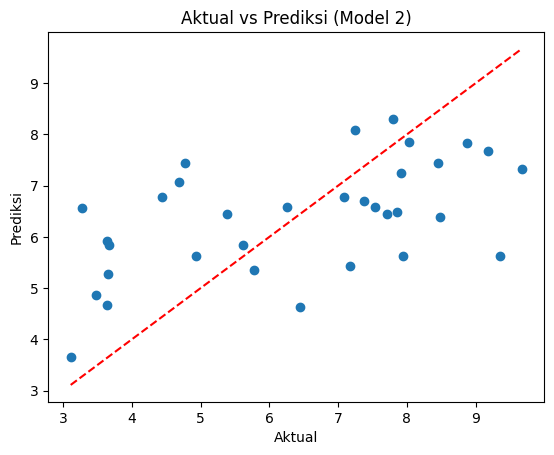

In [23]:
plt.scatter(data["PENGANGGURAN"], m2.fittedvalues)
plt.plot([data["PENGANGGURAN"].min(), data["PENGANGGURAN"].max()],
         [data["PENGANGGURAN"].min(), data["PENGANGGURAN"].max()], "r--")
plt.xlabel("Aktual")
plt.ylabel("Prediksi")
plt.title("Aktual vs Prediksi (Model 2)")
plt.show()

# Kesimpulan

1. Variabel Signifikan: Tidak ada variabel bebas (bm_ekonomi, bm_lingkungan, bm_kesehatan) yang berpengaruh signifikan secara statistik terhadap pengangguran pada taraf nyata 5% (p > 0,05).
2. Nilai R-squared: R-squared Pooled OLS sebesar 0,0980 (9,80%) dan Fixed Effect sebesar 0,2940 (29,40%). Artinya, kemampuan variabel independen dalam menjelaskan tingkat pengangguran masih tergolong rendah dan sebagian besar dipengaruhi faktor lain di luar model.
3. Uji Multikolinearitas (VIF): Aman. Seluruh nilai VIF berada di kisaran 1,031 hingga 1,086 (jauh di bawah 10), sehingga tidak ada masalah multikolinearitas.
4. Perbandingan Model: Berdasarkan nilai AIC, model Fixed Effect (AIC: 139,9) sedikit lebih baik dibanding Pooled OLS (AIC: 144,0), karena penambahan efek kota menaikkan R-squared menjadi 29,40%. Efek kota yang signifikan hanya Pekanbaru, dengan pengangguran sekitar 2,17 poin lebih tinggi dibanding Dumai (p = 0,012).
